In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt 

project_dir = Path(
    r"D:\Nexzibyte Solution\nexzibyte-predictive-bi"
)

clean_path = (
    project_dir / "data" / "clean"
    / "Day3_Prospects_Clean.csv"
)

df = pd.read_csv(clean_path)

print("DAY 4: EXPLORATORY DATA ANALYSIS")
print("-" * 45)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nProspect classifications:")
display(df["Prospect Classification"].value_counts(dropna=False))

print("\nIndustry distribution:")
display(
    df["Industry / Sub-industry"]
    .value_counts()
    .head(15)
)

print("\nCompany-size score distribution:")
display(df["Company Size Score"].value_counts().sort_index())

print("\nProspect score summary:")
display(df["Prospect Score"].describe())

DAY 4: EXPLORATORY DATA ANALYSIS
---------------------------------------------
Rows: 180
Columns: 28

Prospect classifications:


Prospect Classification
High Potential      129
Medium Potential     51
Name: count, dtype: int64


Industry distribution:


Industry / Sub-industry
B2B SaaS / Enterprise Software             72
AI / ML / GenAI                            52
FinTech / Payments                         39
Customer Engagement SaaS / MarTech          2
SaaS / Business Software / AI               1
API Development / B2B SaaS                  1
Software Testing / DevOps SaaS              1
FinTech / Digital Payments                  1
FinTech / Brokerage Technology              1
SaaS / Subscription Billing                 1
Enterprise Software / SaaS                  1
HRTech / Enterprise SaaS                    1
B2B SaaS / Digital Adoption                 1
CRM / Sales & Marketing Automation SaaS     1
FinTech / Enterprise SaaS / AI              1
Name: count, dtype: int64


Company-size score distribution:


Company Size Score
12     35
16     30
20    115
Name: count, dtype: int64


Prospect score summary:


count    180.000000
mean      79.305556
std        9.525677
min       55.000000
25%       74.000000
50%       80.000000
75%       84.000000
max      100.000000
Name: Prospect Score, dtype: float64

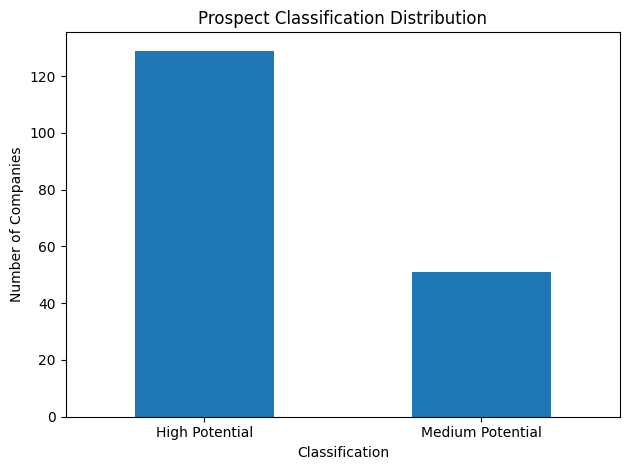

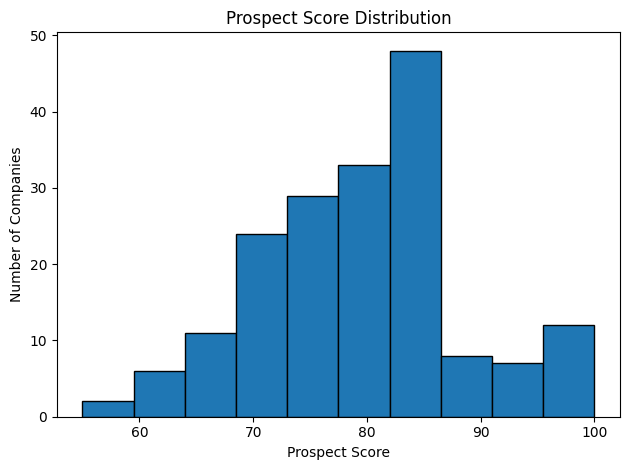

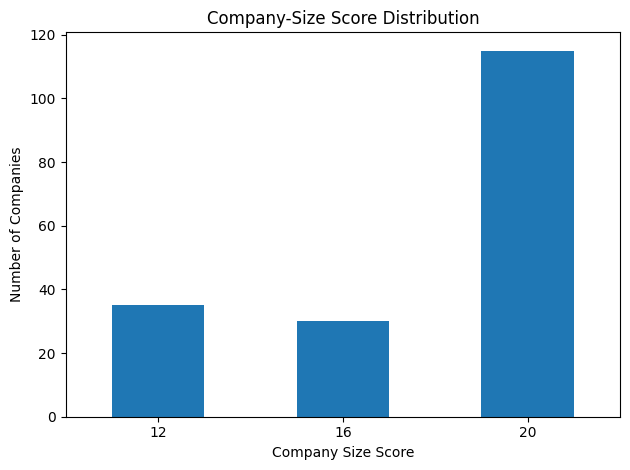

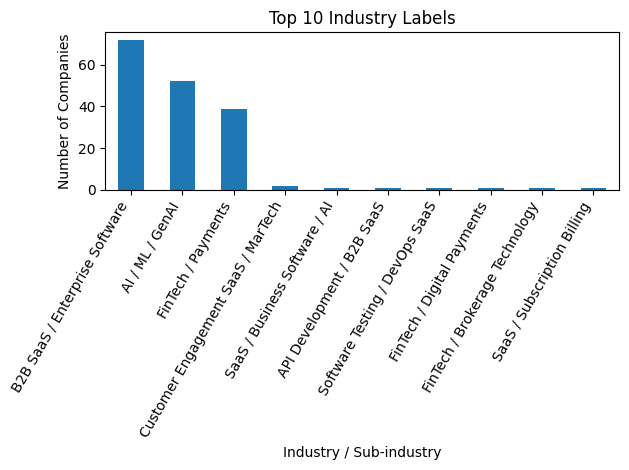

In [2]:
# Day 4: Exploratory Data Analysis Visualizations

# 1. Prospect classification
df["Prospect Classification"].value_counts().plot(
    kind="bar",
    title="Prospect Classification Distribution"
)
plt.xlabel("Classification")
plt.ylabel("Number of Companies")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Prospect score distribution
df["Prospect Score"].plot(
    kind="hist",
    bins=10,
    edgecolor="black",
    title="Prospect Score Distribution"
)
plt.xlabel("Prospect Score")
plt.ylabel("Number of Companies")
plt.tight_layout()
plt.show()

# 3. Company-size score distribution
df["Company Size Score"].value_counts().sort_index().plot(
    kind="bar",
    title="Company-Size Score Distribution"
)
plt.xlabel("Company Size Score")
plt.ylabel("Number of Companies")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Top 10 industry labels
df["Industry / Sub-industry"].value_counts().head(10).plot(
    kind="bar",
    title="Top 10 Industry Labels"
)
plt.xlabel("Industry / Sub-industry")
plt.ylabel("Number of Companies")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [3]:
# Day 4: Prospect Score Component Analysis

score_columns = [
    "Company Size Score",
    "B2B Fit Score",
    "Technology Signal Score",
    "Business Need Score",
    "Recent Business Signal Score",
    "Decision-Maker Score"
]

# Summary of all scoring components
display(df[score_columns + ["Prospect Score"]].describe().T)

# Average component scores by existing classification
classification_summary = (
    df.groupby("Prospect Classification")[score_columns + ["Prospect Score"]]
    .mean()
    .round(2)
)

display(classification_summary)

# Correlation between score components and overall Prospect Score
correlation = df[score_columns + ["Prospect Score"]].corr()

display(correlation[["Prospect Score"]].sort_values(
    "Prospect Score", ascending=False
))

,count,mean,std,min,25%,50%,75%,max
Company Size Score,180.0,17.777778,3.198386,12.0,16.0,20.0,20.0,20.0
B2B Fit Score,180.0,17.388889,4.799196,5.0,15.0,20.0,20.0,20.0
Technology Signal Score,180.0,18.377778,3.259975,5.0,20.0,20.0,20.0,20.0
Business Need Score,180.0,13.972222,2.781484,5.0,15.0,15.0,15.0,15.0
Recent Business Signal Score,180.0,6.388889,3.467952,5.0,5.0,5.0,5.0,15.0
Decision-Maker Score,180.0,5.400000,2.544794,4.0,4.0,4.0,4.0,10.0
Prospect Score,180.0,79.305556,9.525677,55.0,74.0,80.0,84.0,100.0


,Company Size Score,B2B Fit Score,Technology Signal Score,Business Need Score,Recent Business Signal Score,Decision-Maker Score,Prospect Score
Prospect Classification,,,,,,,
High Potential,17.83,19.46,19.37,14.50,6.86,5.81,83.83
Medium Potential,17.65,12.16,15.86,12.65,5.20,4.35,67.86


,Prospect Score
Prospect Score,1.000000
B2B Fit Score,0.599237
Recent Business Signal Score,0.595890
Decision-Maker Score,0.564400
Technology Signal Score,0.445658
Business Need Score,0.326086
Company Size Score,0.246119
